# H₂ molecular Hamiltonian and variational simulation

**Question:** how do mapping, variational-solver, classical-method, and basis errors differ in a controlled molecular calculation?

Compare a four-qubit STO-3G simulation with RHF, restricted PBE DFT, and FCI, then probe basis sensitivity with cc-pVDZ. All molecular energies include nuclear repulsion. Calculations use the nonrelativistic Born–Oppenheimer approximation and exact circuit expectations. Execution instructions and profiles: [README_H2.md](README_H2.md).


In [1]:
import os, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from h2_benchmark import historical_analysis, run_scan, classical_point, provenance, require, real_pauli_hamiltonian

profile = os.environ.get("H2_PROFILE", "default")
if profile not in {"smoke", "default", "extended"}:
    raise ValueError("Unknown H2_PROFILE")
distances = {"smoke": [.74, 2.0],
             "default": [.5, .65, .74, 1., 1.5, 2., 3.],
             "extended": np.linspace(.45, 3., 22).tolist()}[profile]
metadata = provenance()
print(json.dumps(metadata, indent=2))

{
  "python": "3.11.15",
  "packages": {
    "numpy": "1.26.4",
    "scipy": "1.17.1",
    "pennylane": "0.36.0",
    "autoray": "0.6.11",
    "pennylane-lightning": "0.37.0",
    "pyscf": "2.11.0",
    "h5py": "3.16.0",
    "matplotlib": "3.11.2",
    "nbclient": "0.11.0",
    "nbformat": "5.11.1",
    "ipykernel": "7.4.0"
  },
  "energy_convention": "Born-Oppenheimer total energy including nuclear repulsion",
  "geometry_unit": "angstrom",
  "charge": 0,
  "multiplicity": 1,
  "dft": "restricted PBE",
  "requested_pyscf_threads": 1,
  "scf_energy_tolerance_hartree": 1e-11,
  "fci_tolerance": 1e-12,
  "optimizer": "bounded scalar, theta in [-pi, pi], xatol=1e-12, maxiter=200",
  "basis": "sto-3g",
  "frozen_orbitals": 0,
  "spin_orbital_order": "alpha,beta interleaved",
  "measurement": "exact analytic expectation, no shots",
  "bohr_angstrom": 0.529177210903,
  "benchmark_source_sha256": "df7caa20ad3fa2b8221fd88346d6f048d40f68ae369d65f38b918806ef2f5592"
}


pyscf/lib/misc.py:148: UserWarning: OpenMP is not available. Setting omp_threads to 1 has no effects.
  warnings.warn('OpenMP is not available. '


## 1. Geometry, basis, and molecular integrals

Use H at $(0,0,0)$ and $(0,0,R)$ in Å, charge 0, singlet multiplicity, STO-3G, and no frozen orbitals: two electrons, two spatial orbitals, four spin orbitals. Convert Å to bohr explicitly for PennyLane 0.36. RHF molecular orbitals define the integral basis.

For spin orbitals, using the ordering $g_{pqrs}=\langle pq|sr\rangle$,

$$H=E_{\mathrm{nuc}}I+\sum_{pq}h_{pq}a_p^\dagger a_q+\frac12\sum_{pqrs}g_{pqrs}a_p^\dagger a_q^\dagger a_r a_s.$$

Here $g_{pqrs}=\int\chi_p^*(1)\chi_q^*(2)r_{12}^{-1}\chi_r(2)\chi_s(1)\,d1\,d2$. PennyLane returns spatial integral tensors and expands spin indices when constructing the fermionic operator. The scalar is nuclear repulsion here; frozen-core contributions would also enter it in an active-space model.


In [2]:
import pennylane as qml
from scipy.optimize import minimize_scalar
from h2_benchmark import coordinates_bohr

symbols = ["H", "H"]
R_angstrom = 0.74
geometry_bohr = qml.numpy.array(coordinates_bohr(R_angstrom), requires_grad=False)
molecule = qml.qchem.Molecule(symbols, geometry_bohr, charge=0, mult=1, basis_name="sto-3g")
constant, one_electron, two_electron = qml.qchem.electron_integrals(molecule)()
require((molecule.n_electrons, molecule.n_orbitals) == (2, 2), "Unexpected molecular model")
require(one_electron.shape == (2, 2) and two_electron.shape == (2, 2, 2, 2), "Integral dimensions")
np.testing.assert_allclose(np.asarray(constant).item(), 1 / geometry_bohr[1,2], atol=1e-12, rtol=0)
print("Geometry / bohr:\n", geometry_bohr)
print("Nuclear repulsion / Ha:", np.asarray(constant).item())
print("One-electron MO integrals / Ha:\n", np.asarray(one_electron))
print("Two-electron tensor shape:", two_electron.shape)
print("g0000 and g0110 / Ha:", float(two_electron[0,0,0,0]), float(two_electron[0,1,1,0]))


Geometry / bohr:
 [[0.         0.         0.        ]
 [0.         0.         1.39839733]]
Nuclear repulsion / Ha: 0.715104339058108
One-electron MO integrals / Ha:
 [[-1.25330979e+00 -2.10831352e-13]
 [-2.10942375e-13 -4.75068855e-01]]
Two-electron tensor shape: (2, 2, 2, 2)
g0000 and g0110 / Ha: 0.6747559282972692 0.6637114004228314


## 2. Fermionic Hamiltonian and Jordan–Wigner mapping

Construct the fermionic operator from those same tensors, then map to qubits with
$a_p^\dagger=(\prod_{j<p}Z_j)(X_p-iY_p)/2$. Molecular wire order is `[0,1,2,3]`, with interleaved α/β orbitals; the leftmost statevector bit is wire 0. The mapped Pauli identity coefficient generally differs from $E_{\mathrm{nuc}}$ because electronic terms also contribute to it.

A Hermitian Pauli expansion has real coefficients. Validate finiteness and imaginary parts before normalizing a complex storage dtype; verify that the matrix is unchanged.


In [3]:
fermion_hamiltonian = qml.qchem.fermionic_observable(constant, one_electron, two_electron)
raw_qubit_hamiltonian = qml.jordan_wigner(fermion_hamiltonian)
qubit_hamiltonian = real_pauli_hamiltonian(raw_qubit_hamiltonian)
np.testing.assert_allclose(qml.matrix(raw_qubit_hamiltonian, wire_order=range(4)),
                           qml.matrix(qubit_hamiltonian, wire_order=range(4)), atol=1e-12, rtol=0)
H_matrix = np.asarray(qml.matrix(qubit_hamiltonian, wire_order=range(4)))
H_api, qubits = qml.qchem.molecular_hamiltonian(
    symbols, geometry_bohr, charge=0, mult=1, basis="sto-3g", method="dhf", mapping="jordan_wigner")
np.testing.assert_allclose(H_matrix, qml.matrix(H_api, wire_order=range(4)), atol=1e-12, rtol=0)
np.testing.assert_allclose(H_matrix, H_matrix.conj().T, atol=1e-12, rtol=0)
require(qubits == 4, "Unexpected qubit count")
print("Fermionic terms:", len(fermion_hamiltonian))
print("Qubits / Pauli terms:", qubits, len(qubit_hamiltonian.terms()[0]))
print(qubit_hamiltonian)


Fermionic terms: 37
Qubits / Pauli terms: 4 15
-0.09706627631494774 * I() + 0.171412826794691 * Z(0) + -0.22343153267815835 * Z(2) + 0.12062523475281105 * (Z(0) @ Z(2)) + 0.17141282679469103 * Z(1) + 0.1686889820743173 * (Z(0) @ Z(1)) + 0.04530261535289679 * (Y(0) @ X(1) @ X(2) @ Y(3)) + -0.04530261535289679 * (Y(0) @ Y(1) @ X(2) @ X(3)) + -0.04530261535289679 * (X(0) @ X(1) @ Y(2) @ Y(3)) + 0.04530261535289679 * (X(0) @ Y(1) @ Y(2) @ X(3)) + -0.22343153267815835 * Z(3) + 0.16592785010570785 * (Z(0) @ Z(3)) + 0.12062523475281105 * (Z(1) @ Z(3)) + 0.16592785010570785 * (Z(1) @ Z(2)) + 0.17441287534863525 * (Z(2) @ Z(3))


## 3. Hartree–Fock state, ansatz, and variational optimization

Prepare $|1100\rangle$ and apply one double excitation. For symmetric H₂/STO-3G, this spans the relevant paired-determinant singlet block. Optimize the circuit expectation without using the exact reference; a scalar optimizer is sufficient for this one-parameter problem. The reference is computed afterward in $N_\alpha=N_\beta=1$ and compared with independently implemented PySCF FCI. Fixing $S_z=0$ alone does not fix total spin.


In [4]:
hf_bits = qml.qchem.hf_state(2, qubits)
device = qml.device("default.qubit", wires=qubits)

@qml.qnode(device)
def energy_circuit(theta):
    qml.BasisState(hf_bits, wires=range(qubits))
    qml.DoubleExcitation(theta, wires=range(qubits))
    return qml.expval(qubit_hamiltonian)

optimum = minimize_scalar(lambda theta: float(energy_circuit(theta)), bounds=(-np.pi, np.pi),
                          method="bounded", options={"xatol": 1e-12, "maxiter": 200})
require(optimum.success, "Variational optimizer failed")
sector = [i for i in range(16) if sum(map(int, f"{i:04b}"[::2])) == 1
          and sum(map(int, f"{i:04b}"[1::2])) == 1]
sector_exact = float(np.linalg.eigvalsh(H_matrix[np.ix_(sector, sector)])[0])
reference = classical_point(R_angstrom)
np.testing.assert_allclose(sector_exact, reference["fci_hartree"], atol=2e-7, rtol=0)
np.testing.assert_allclose(float(energy_circuit(0.0)), reference["rhf_hartree"], atol=2e-7, rtol=0)
require(-1e-10 <= float(optimum.fun) - sector_exact < 1e-8, "Variational energy check failed")
print("HF occupations:", hf_bits)
print(qml.draw(energy_circuit)(float(optimum.x)))
print("Optimized angle:", float(optimum.x), "| circuit evaluations:", optimum.nfev)
print("VQE / sector exact / PySCF FCI (Ha):", float(optimum.fun), sector_exact, reference["fci_hartree"])


HF occupations:

 [1 1 0 0]
0: ─╭|Ψ⟩─╭G²(0.23)─┤ ╭<𝓗>
1: ─├|Ψ⟩─├G²(0.23)─┤ ├<𝓗>
2: ─├|Ψ⟩─├G²(0.23)─┤ ├<𝓗>
3: ─╰|Ψ⟩─╰G²(0.23)─┤ ╰<𝓗>
Optimized angle: 0.2255656813572679 | circuit evaluations: 12
VQE / sector exact / PySCF FCI (Ha): -1.1372838347085392 -1.1372838347085392 -1.1372838344885023


## 4. Potential-energy scan and classical benchmarks

The tested scan utilities repeat construction and optimization at every distance. PySCF uses RHF, RKS-PBE (grid level 3), and FCI; nonconverged solvers fail explicitly. Acceptance requires independent reference/HF agreement within $2\times10^{-7}$ Ha, VQE gap in $[-10^{-10},10^{-8})$ Ha, sector leakage below $10^{-12}$, variance below $10^{-10}$ Ha², electron number two within $10^{-12}$, and singlet $\langle S^2\rangle$ within $10^{-10}$.

RHF and VQE obey the wavefunction variational bound. PBE–FCI differences are signed method comparisons and may be negative. All geometries and energy conventions are matched.


In [5]:
rows = run_scan(distances)
print("R / A     RHF / Ha       PBE / Ha       FCI / Ha       VQE gap / Ha")
for r in rows:
    print(f"{r['distance_angstrom']:5.2f}  {r['rhf_hartree']: .9f}  {r['rks_pbe_hartree']: .9f}  {r['fci_hartree']: .9f}  {r['vqe_gap_hartree']:.2e}")

R / A     RHF / Ha       PBE / Ha       FCI / Ha       VQE gap / Ha
 0.50  -1.042996275  -1.070662508  -1.055159794  0.00e+00
 0.65  -1.112996546  -1.144796434  -1.129904784  -4.44e-16
 0.74  -1.116759307  -1.152072795  -1.137283834  0.00e+00
 1.00  -1.066108649  -1.115433019  -1.101150330  0.00e+00
 1.50  -0.910873555  -0.998737564  -0.998149353  -1.11e-16
 2.00  -0.783792654  -0.911485895  -0.948641112  0.00e+00
 3.00  -0.656048251  -0.836989045  -0.933631845  0.00e+00


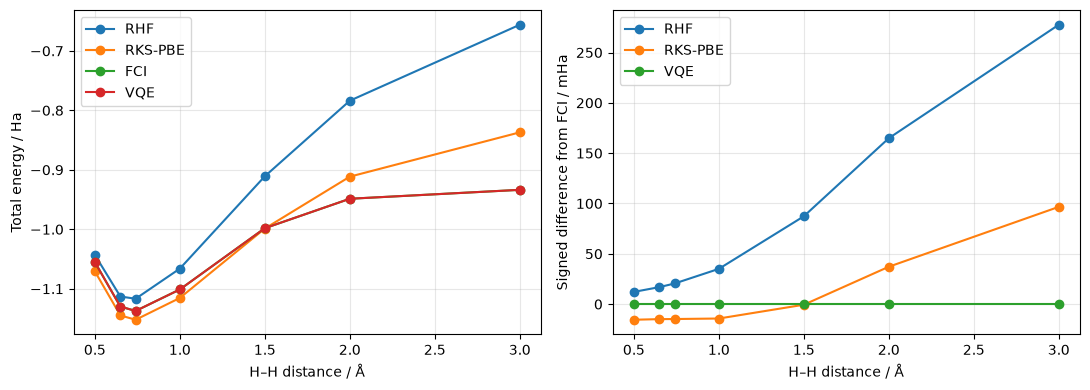

Maximum VQE gap / Ha: 0.0
Maximum energy variance / Ha²: 9.764368536693663e-17


In [6]:
r = np.array([x["distance_angstrom"] for x in rows])
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for key,label in [("rhf_hartree","RHF"),("rks_pbe_hartree","RKS-PBE"),
                  ("fci_hartree","FCI"),("vqe_hartree","VQE")]:
    y = np.array([x[key] for x in rows])
    axes[0].plot(r,y,"o-",label=label)
    if key != "fci_hartree":
        axes[1].plot(r,1000*(y-np.array([x["fci_hartree"] for x in rows])),"o-",label=label)
axes[0].set(xlabel="H–H distance / Å",ylabel="Total energy / Ha")
axes[1].set(xlabel="H–H distance / Å",ylabel="Signed difference from FCI / mHa")
for ax in axes: ax.legend(); ax.grid(alpha=.3)
fig.tight_layout()
plt.show()
print("Maximum VQE gap / Ha:", max(x["vqe_gap_hartree"] for x in rows))
print("Maximum energy variance / Ha²:", max(x["variance_hartree2"] for x in rows))

## 5. Basis and integration-grid controls

At 0.74 Å, repeat the classical calculations in cc-pVDZ and compare PBE/STO-3G grid levels 3 and 5 (tolerance 10⁻⁶ Ha). The FCI basis difference measures sensitivity at one geometry; it is not a complete-basis error estimate. The grid check applies at that geometry only.


In [7]:
small_basis = classical_point(.74)
large_basis = classical_point(.74, basis="cc-pvdz")
fine_grid = classical_point(.74, grid_level=5)
grid_shift = fine_grid["rks_pbe_hartree"]-small_basis["rks_pbe_hartree"]
require(abs(grid_shift) < 1e-6, "PBE integration grid control failed")
print("Basis controls:", json.dumps([small_basis,large_basis], indent=2))
print("PBE grid 5 minus grid 3 / Ha:", grid_shift)
print("cc-pVDZ minus STO-3G FCI / Ha:", large_basis["fci_hartree"]-small_basis["fci_hartree"])

Basis controls: [
  {
    "distance_angstrom": 0.74,
    "basis": "sto-3g",
    "rhf_hartree": -1.1167593073964253,
    "fci_hartree": -1.1372838344885023,
    "rks_pbe_hartree": -1.1520727950373097,
    "grid_level": 3,
    "nuclear_repulsion_hartree": 0.7151043390810812,
    "rhf_converged": true,
    "fci_converged": true,
    "rks_converged": true,
    "fci_spin_squared": 7.253686828806149e-33,
    "fci_natural_occupations": [
      1.9746677470459593,
      0.025332252954040884
    ]
  },
  {
    "distance_angstrom": 0.74,
    "basis": "cc-pvdz",
    "rhf_hartree": -1.1287000935564415,
    "fci_hartree": -1.1633744903192407,
    "rks_pbe_hartree": -1.1598470811161543,
    "grid_level": 3,
    "nuclear_repulsion_hartree": 0.7151043390810812,
    "rhf_converged": true,
    "fci_converged": true,
    "rks_converged": true,
    "fci_spin_squared": 1.4144837226669627e-32,
    "fci_natural_occupations": [
      1.966478924089933,
      0.020395976449696863,
      0.006095540088856434,
 

## 6. Static correlation

FCI spin-summed natural occupations sum to two. Their evolution from approximately (2, 0) toward (1, 1) diagnoses increasing multireference character within STO-3G. Restricted HF retains one doubly occupied orbital; the excitation circuit can mix paired determinants in this special case. Export electron-number, spin, variance, and sector-leakage diagnostics alongside energies.


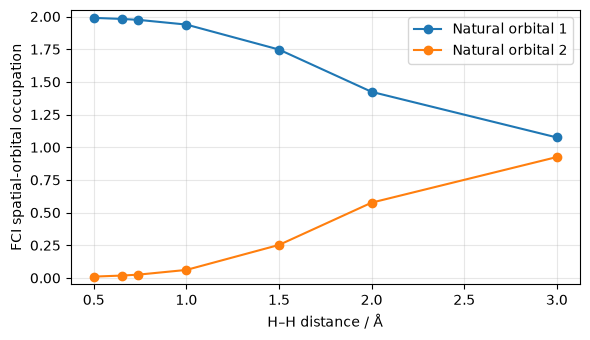

Maximum |S²| (VQE): 0.0
Electron counts: [2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0]
Endpoint natural occupations: [[1.9896772597196342, 0.01032274028036573], [1.0748882302119165, 0.9251117697880831]]


In [8]:
occupations = np.array([x["fci_natural_occupations"] for x in rows])
correlation_fig, ax = plt.subplots(figsize=(6, 3.5))
for i in range(2):
    ax.plot(r, occupations[:,i], "o-", label=f"Natural orbital {i+1}")
ax.set(xlabel="H–H distance / Å", ylabel="FCI spatial-orbital occupation", ylim=(-.05,2.05))
ax.grid(alpha=.3)
ax.legend()
correlation_fig.tight_layout()
plt.show()
print("Maximum |S²| (VQE):", max(abs(x["vqe_spin_squared"]) for x in rows))
print("Electron counts:", [round(x["vqe_particle_number"],12) for x in rows])
print("Endpoint natural occupations:", occupations[[0,-1]].tolist())


## 7. Analytical cross-check: historical Pauli model

This separate coefficient table has no verified geometry, integral, or nuclear-offset provenance. Test it as algebra only. In wire order `[3,2,1,0]`, let $|a\rangle=|0011\rangle$, $|b\rangle=|1100\rangle$ and

$$H_{ab}=\begin{pmatrix}E_a&v\\v&E_b\end{pmatrix},\quad v=2(c_9-c_8),\quad C=(E_a+E_b)/2,\quad d=(E_a-E_b)/2.$$

For $\cos\theta|a\rangle-\sin\theta|b\rangle$,
$$E(\theta)=C+d\cos(2\theta)-v\sin(2\theta),\qquad E_{\min}=C-\sqrt{d^2+v^2}.$$

For $e^{-i\beta H_0}e^{-i\gamma V}|a\rangle$,
$$E(\beta,\gamma)=C+d\cos(2v\gamma)+v\sin(2v\gamma)\sin[\beta(E_a-E_b)].$$

Tests verify the invariant subspace, Pauli phases, basis conventions, and matrix evolution. This subspace minimum is distinct from a full-Fock-space minimum.


In [9]:
algebra = historical_analysis()
print("Two-state block (historical coefficient units):\n", algebra["block"])
print("Coupling:", algebra["coupling"])
print("Analytical minimum:", algebra["analytic_min"])
print("Direct expectation:", algebra["expectation"])
np.testing.assert_allclose(algebra["expectation"], algebra["analytic_min"], atol=1e-12, rtol=0)
np.testing.assert_allclose(algebra["analytic_min"], np.linalg.eigvalsh(algebra["block"])[0], atol=1e-12, rtol=0)

Two-state block (historical coefficient units):
 [[-0.975383  0.141412]
 [ 0.141412  0.293333]]
Coupling: 0.141412
Analytical minimum: -0.9909537852588158
Direct expectation: -0.9909537852588158


## 8. Evidence and limitations

Save geometries, energies, solver settings, diagnostics, versions, and source digest. Solver agreement is numerical evidence within a finite basis. The basis control and stretched-bond diagnostics quantify separate modeling limitations. The sampled minimum is not an optimized geometry; these calculations do not establish dissociation energies, thermal free energies, experimental accuracy, hardware performance, or quantum advantage.


In [10]:
evidence = {"profile":profile,"provenance":metadata,"scan":rows,
            "basis_controls":[small_basis,large_basis],
            "pbe_grid_shift_hartree":grid_shift}
output_dir = Path(os.environ.get("H2_OUTPUT_DIR", "artifacts/h2"))
output_dir.mkdir(parents=True, exist_ok=True)
(output_dir/"results.json").write_text(json.dumps(evidence,indent=2)+"\n")
fig.savefig(output_dir/"potential_energy_curve.png",dpi=160)
correlation_fig.savefig(output_dir/"natural_occupations.png",dpi=160)
print("Evidence saved to",output_dir)
print("PASS: numerical acceptance checks at every sampled geometry")

Evidence saved to artifacts/h2
PASS: numerical acceptance checks at every sampled geometry


## References

- [PennyLane 0.36 molecular integrals and Hamiltonian construction](https://docs.pennylane.ai/en/v0.36.0/code/qml_qchem.html).
- [PySCF SCF](https://pyscf.org/user/scf.html), [DFT and grids](https://pyscf.org/user/dft.html), and [FCI](https://pyscf.org/user/ci.html).

Executable validation and tested package versions are recorded in [VALIDATION.md#h2](VALIDATION.md#h2).
